
# Autoencoders & VAEs as Regression — the Swiss Roll

The MNIST notebook framed AEs/VAEs around **images**: high-dimensional,
pixel values bounded to `[0,1]`, reconstructions scored with binary
cross-entropy, digit labels used only for coloring plots.

This notebook is the deliberate opposite case, designed to round out your
understanding: **low**-dimensional, **unbounded**, continuous data, scored
with plain **MSE** — which is the more general, more common setting for
autoencoders outside of image pixels. Same models, same code patterns,
different data — which is exactly the point: if the patterns below feel
familiar, that's a good sign the concepts (not just the MNIST-specific
details) landed.

## The dataset: two interleaved spiral arms

We'll build this from `sklearn.datasets.make_swiss_roll`, viewed from above so
each roll collapses into a 2D spiral, with Gaussian noise scattering points
off the true curve. Critically, this is **two genuinely distinct branches**,
not one spiral arbitrarily cut in half: we generate the swiss-roll curve
twice and rotate the second copy 180°, producing two separate interleaved
arms winding around a shared center — the classic "two spirals" structure
used as a nonlinear-classification benchmark since the 1980s. The label
(which arm a point belongs to) is a real geometric distinction, never used
in training — same unsupervised setup as MNIST's digit labels.

## The framing: reconstruction *as regression*

With a **1-dimensional bottleneck**, an autoencoder trained on this data is
doing something very concrete: finding the single best 1D curve that
threads through a noisy 2D point cloud — learning the identity function
$f(x) \approx x$, but forced through a narrow enough bottleneck that it
can't just memorize each point; it has to find the underlying structure.
That's a regression problem in a very literal sense, and because everything
here is 2D or 1D, you can **see the learned curve directly** — something
that was impossible with 784-pixel MNIST digits. It also sets up a genuine
tension worth watching for: a single 1D curve fundamentally cannot trace two
separate, disjoint arms without some kind of compromise — keep an eye out
for exactly what that compromise looks like in Section 4.

**Learning objectives:**
- Reuse your AE/VAE building blocks on continuous, unbounded data — and see
  concretely *why* the decoder here has no `Sigmoid` and the loss is MSE,
  not BCE
- Visualize a trained model's bottleneck as an actual regression curve,
  compared against a linear (PCA) baseline
- See how a VAE's 1D latent distribution compares to its prior directly, via
  a histogram instead of a high-dimensional scatter plot
- Test whether an unsupervised bottleneck — trained with no label anywhere
  in its loss — nonetheless preserves enough structure to distinguish two
  genuinely different spiral arms, and see how that answer changes with the
  bottleneck's dimensionality and with a *linear* vs. a *nonlinear* way of
  reading it out
- Get a feel for how noise/stochasticity in the data interacts with a
  bottleneck — why compression acts like a smoother, not an interpolator

Same rules as before: `# TODO` markers are yours to fill in, sanity-check
cells verify you're on track, no solutions are given.


**Algorithms like Isomap, LLE, t-SNE, and autoencoders get benchmarked on whether they can "unroll" it and recover something close to the true 1D/2D structure (i.e., recover t) rather than being fooled by 3D proximity.**


### A note on loss functions used in this notebook

Every model here is trained with a **reconstruction term**, and the VAE
variants add a **KL term** on top. The reconstruction term changes shape
three times across the notebook — worth previewing up front, since they're
all secretly the same idea at different levels of sophistication:

| Section | Model | Reconstruction loss | What it assumes |
|---|---|---|---|
| 2 | AE | `F.mse_loss(x_hat, x)` — plain MSE | Every point is equally uncertain; the model just minimizes average squared distance. |
| 5 | VAE | Summed MSE `/ batch_size` + KL term | Same assumption as the AE — reconstruction is still plain squared error, only the *latent* side gets a distribution (`mu_z`, `logvar_z`) and a KL penalty. |
| 6.5 | Gaussian-decoder VAE | Gaussian negative log-likelihood: `0.5 * sum(logvar_x + (x-mu_x)² / exp(logvar_x))` | The decoder predicts *both* a mean and a variance per point — it learns where it should be confident vs. uncertain, instead of assuming uniform confidence everywhere. |

The key fact tying these together: **MSE is a special case of the Gaussian
NLL used in Section 6.5**, with the variance fixed to a constant instead of
learned. Every model in this notebook is minimizing a negative
log-likelihood under some assumed noise distribution — Sections 2 and 5 just
assume that distribution's variance is fixed and equal for every point,
while Section 6.5 lets the model decide.

Every VAE variant additionally adds:
```
kl_loss = -0.5 * sum(1 + logvar_z - mu_z^2 - exp(logvar_z))
```
— the closed-form KL divergence between the encoder's per-point distribution
`N(mu_z, exp(logvar_z))` and the prior `N(0,1)`, discussed in Section 5.



## 0. Setup


In [116]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_swiss_roll

%matplotlib inline

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")


Using device: cpu



### Hyperparameters

Note `LATENT_DIM = 1` — this is deliberate, not a simplification for
convenience. A 1D bottleneck on 2D data forces the model to find *the*
curve, and lets us visualize it directly by sweeping over every possible
latent value and decoding it.


In [117]:

N_SAMPLES = 2000     # split evenly across the two arms
NOISE = 0.5          # try changing this later — see Section 9

BATCH_SIZE = 64
INPUT_DIM = 2
HIDDEN_DIM = 128
LATENT_DIM = 1        # deliberately 1D — see note above
EPOCHS = 500
LR = 1e-3



## 0.5. Warm-up: a single spiral arm

Before tackling the two-armed dataset above, it's worth seeing the 1D-bottleneck
AE succeed on the *easier*, more standard version of this problem: a single
swiss-roll arm collapsed to 2D, with nothing to compromise between. This is a
fully worked, given example (no TODOs) — its only purpose is to give you a
clean baseline to compare the two-arm zigzag behavior against later.


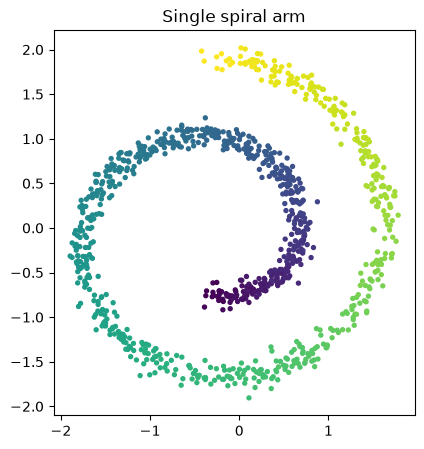

In [118]:

N_SAMPLES_SINGLE = 1000
NOISE_SINGLE = 0.5

X_3d_single, t_single = make_swiss_roll(n_samples=N_SAMPLES_SINGLE, noise=NOISE_SINGLE, random_state=SEED)
X_single_raw = X_3d_single[:, [0, 2]]     # drop the height axis, same as the two-arm case below

X_single_mean, X_single_std = X_single_raw.mean(axis=0), X_single_raw.std(axis=0)
X_single = (X_single_raw - X_single_mean) / X_single_std

perm_single = torch.randperm(len(X_single), generator=torch.Generator().manual_seed(SEED)).numpy()
n_test_single = int(len(X_single) * 0.2)
test_idx_single, train_idx_single = perm_single[:n_test_single], perm_single[n_test_single:]

X_train_single, X_test_single = X_single[train_idx_single], X_single[test_idx_single]

plt.figure(figsize=(5, 5))
plt.scatter(X_single[:, 0], X_single[:, 1], c=t_single, cmap="viridis", s=8)
plt.gca().set_aspect("equal")
plt.title("Single spiral arm")
plt.show()


In [119]:

X_train_single_tensor = torch.FloatTensor(X_train_single)

train_dataset_single = TensorDataset(X_train_single_tensor, X_train_single_tensor)
train_loader_single = DataLoader(train_dataset_single, batch_size=BATCH_SIZE, shuffle=True)


In [120]:

class SingleAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


ae_single = SingleAE().to(device)
optimizer_single = torch.optim.Adam(ae_single.parameters(), lr=LR)

for epoch in range(EPOCHS*100):
    epoch_loss = 0.0
    n_batches = 0
    for x, _ in train_loader_single:
        x = x.to(device)
        x_hat = ae_single(x)
        loss = F.mse_loss(x_hat, x)

        optimizer_single.zero_grad()
        loss.backward()
        optimizer_single.step()

        epoch_loss += loss.item()
        n_batches += 1

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS*100} — loss: {epoch_loss / n_batches:.4f}")


Epoch 100/50000 — loss: 0.1175
Epoch 200/50000 — loss: 0.0941
Epoch 300/50000 — loss: 0.0850
Epoch 400/50000 — loss: 0.0758
Epoch 500/50000 — loss: 0.0725
Epoch 600/50000 — loss: 0.0704
Epoch 700/50000 — loss: 0.0665
Epoch 800/50000 — loss: 0.0648
Epoch 900/50000 — loss: 0.0634
Epoch 1000/50000 — loss: 0.0613
Epoch 1100/50000 — loss: 0.0617
Epoch 1200/50000 — loss: 0.0650
Epoch 1300/50000 — loss: 0.0624
Epoch 1400/50000 — loss: 0.0565
Epoch 1500/50000 — loss: 0.0570
Epoch 1600/50000 — loss: 0.0982
Epoch 1700/50000 — loss: 0.0536
Epoch 1800/50000 — loss: 0.0544
Epoch 1900/50000 — loss: 0.0525
Epoch 2000/50000 — loss: 0.0525
Epoch 2100/50000 — loss: 0.0530
Epoch 2200/50000 — loss: 0.0502
Epoch 2300/50000 — loss: 0.0507
Epoch 2400/50000 — loss: 0.0508
Epoch 2500/50000 — loss: 0.0501
Epoch 2600/50000 — loss: 0.0509
Epoch 2700/50000 — loss: 0.0516
Epoch 2800/50000 — loss: 0.0501
Epoch 2900/50000 — loss: 0.0526
Epoch 3000/50000 — loss: 0.0492
Epoch 3100/50000 — loss: 0.0480
Epoch 3200/50000 

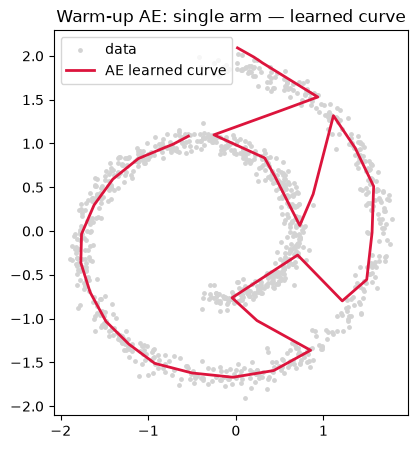

In [121]:

ae_single.eval()
with torch.no_grad():
    z_single = ae_single.encoder(torch.FloatTensor(X_train_single).to(device)).cpu().numpy()

z_sweep_single = np.linspace(z_single.min(), z_single.max(), 200).reshape(-1, 1)
with torch.no_grad():
    curve_single = ae_single.decoder(torch.FloatTensor(z_sweep_single).to(device)).cpu().numpy()

plt.figure(figsize=(5, 5))
plt.scatter(X_single[:, 0], X_single[:, 1], s=6, color="lightgray", label="data")
plt.plot(curve_single[:, 0], curve_single[:, 1], color="crimson", linewidth=2, label="AE learned curve")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Warm-up AE: single arm — learned curve")
plt.show()



## 1. Data: two interleaved spiral arms

`make_swiss_roll` returns 3D points lying on a rolled-up sheet; we keep only
2 of the 3 coordinates, which collapses it into a 2D spiral (the dropped
axis is just the "height" of the roll and carries no structure worth
keeping here).

To get **two genuinely distinct branches** rather than one spiral cut in
half, we generate this twice and rotate the second copy 180° around the
origin. Since the swiss-roll formula is $x=t\cos t,\; z=t\sin t$, rotating
by $\pi$ radians is just $(x,z)\mapsto(-x,-z)$ — literally negating both
coordinates of the second batch. The result is two arms that wind around a
shared center, always on opposite sides of it, interleaving without
touching: the classic "two spirals" dataset.

We also **standardize** the coordinates (zero mean, unit variance) before
doing anything else. This wasn't necessary for MNIST — pixels already arrive
in a small, consistent `[0,1]` range — but raw swiss-roll coordinates span a
much wider, off-center range, and unnormalized inputs like that routinely
slow down or destabilize neural network training. Standardizing first is
standard practice for basically any non-image tabular/continuous data.

This part is boilerplate, given in full.


Train: (1600, 2), Test: (400, 2)


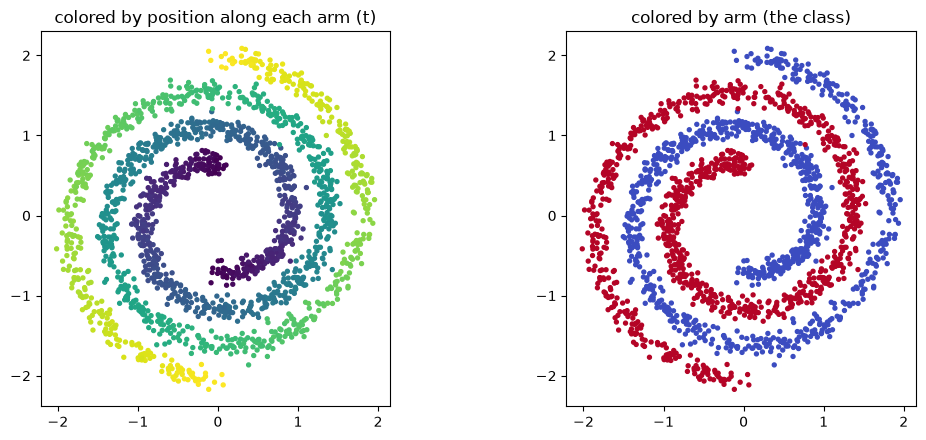

In [122]:

n_per_arm = N_SAMPLES // 2

X_3d_a, t_a = make_swiss_roll(n_samples=n_per_arm, noise=NOISE, random_state=SEED)
X_a = X_3d_a[:, [0, 2]]                              # arm 0, dropped height axis

X_3d_b, t_b = make_swiss_roll(n_samples=n_per_arm, noise=NOISE, random_state=SEED + 1)
X_b = -X_3d_b[:, [0, 2]]                             # arm 1, rotated 180 degrees

X_raw = np.vstack([X_a, X_b])
t = np.concatenate([t_a, t_b])                       # position along whichever arm
labels = np.concatenate([np.zeros(n_per_arm), np.ones(n_per_arm)]).astype(int)

X_mean, X_std = X_raw.mean(axis=0), X_raw.std(axis=0)
X = (X_raw - X_mean) / X_std                         # standardize once, use everywhere below

# Manual train/test split — a fixed-seed torch.randperm instead of
# sklearn's train_test_split, so the split itself is plain PyTorch too.
n = X.shape[0]
perm = torch.randperm(n, generator=torch.Generator().manual_seed(SEED)).numpy()
n_test = int(n * 0.2)
test_idx, train_idx = perm[:n_test], perm[n_test:]

X_train, X_test = X[train_idx], X[test_idx]
t_train, t_test = t[train_idx], t[test_idx]
y_train, y_test = labels[train_idx], labels[test_idx]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], c=t, cmap="viridis", s=8)
axes[0].set_title("colored by position along each arm (t)")
axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=8)
axes[1].set_title("colored by arm (the class)")
for ax in axes:
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()



### Your task: wrap the data in a `DataLoader`

MNIST came with `torchvision` handling this; here we build it ourselves from
a plain numpy array.

1. Convert `X_train` to a `torch.FloatTensor`.
2. Wrap it in a `TensorDataset`. `TensorDataset` needs at least one tensor,
   but conventionally pairs data with a target — since we're reconstructing
   the input itself (there's no separate label to predict), pass the same
   tensor twice: `TensorDataset(X_tensor, X_tensor)`. This isn't just a
   workaround — it's a literal statement of the task: *the input is its own
   target*, i.e. the identity function.
3. Wrap that in a `DataLoader` with `batch_size=BATCH_SIZE, shuffle=True`.

Do the same for `X_test` (`shuffle=False` for test data, by convention).


In [123]:
X_train_tensor = torch.FloatTensor(X_train)
X_test_tensor = torch.FloatTensor(X_test)

train_dataset = TensorDataset(X_train_tensor, X_train_tensor)
test_dataset = TensorDataset(X_test_tensor, X_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


In [124]:

# Sanity check
xb, yb = next(iter(train_loader))
assert xb.shape == (BATCH_SIZE, INPUT_DIM) or xb.shape[0] <= BATCH_SIZE
assert torch.equal(xb, yb), "the dummy target should be identical to the input"
print("DataLoader looks correct. Batch shape:", xb.shape)


DataLoader looks correct. Batch shape: torch.Size([64, 2])



## 2. Autoencoder (AE)

### Theory: same architecture, different output layer

The encoder/decoder shape is identical to the MNIST notebook:

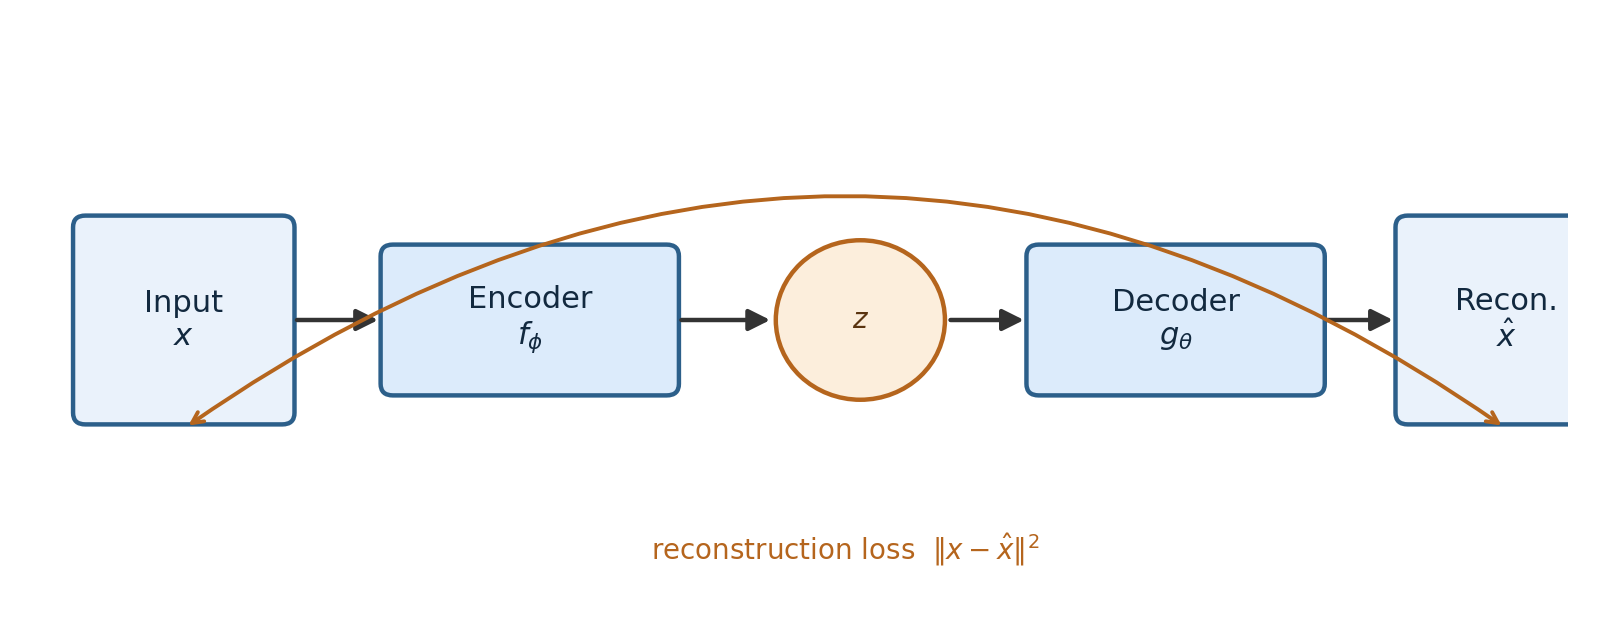

$$
\mathcal{L}_{\text{AE}}(\theta, \phi) = \frac{1}{N}\sum_{i=1}^{N} \left\lVert x_i - g_\theta\big(f_\phi(x_i)\big) \right\rVert_2^2
$$

But look closely at what changes:

> **No `Sigmoid` on the decoder's output this time.** `Sigmoid` exists to
> squash outputs into `[0,1]` to match pixel intensities and to satisfy BCE's
> requirement that its inputs be strictly between 0 and 1. Our swiss roll
> coordinates are unbounded, ordinary real numbers — nothing constrains them
> to any particular range, so nothing should squash the decoder's output.
> The very last layer is just a plain `nn.Linear`, full stop.
>
> **MSE, not BCE.** Squared error is what the general AE objective is
> written in terms of, and there's no probabilistic pixel-intensity
> interpretation to justify BCE here. MSE is simply "how far is the
> reconstructed point from the real point," which is exactly what we want
> to measure for continuous coordinates.

Everything else — the encoder compressing to a bottleneck, the decoder
expanding back out, training by gradient descent — is unchanged.



### Your task: implement `Encoder`, `Decoder`, `Autoencoder`

Same shapes as the MNIST notebook, with `INPUT_DIM = 2` and
`LATENT_DIM = 1` this time:

- `Encoder`: `Linear(input_dim, hidden_dim)` → `ReLU` → `Linear(hidden_dim, latent_dim)`
- `Decoder`: `Linear(latent_dim, hidden_dim)` → `ReLU` → `Linear(hidden_dim, output_dim)`
  — **no activation after the last layer.**
- `Autoencoder`: wires the two together, `forward(x)` returns `x_hat`.


In [125]:

class Encoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)

        )

    def forward(self, x):
        z = self.net(x)
        return z


class Decoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, hidden_dim=HIDDEN_DIM, output_dim=INPUT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, z):
        x = self.net(z)
        return x


class Autoencoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon




In [126]:

# Sanity check
ae = Autoencoder().to(device)
dummy_x = torch.randn(4, INPUT_DIM).to(device)   # note: randn, not rand — unbounded now
dummy_x_hat = ae(dummy_x)

assert dummy_x_hat.shape == dummy_x.shape
assert torch.isfinite(dummy_x_hat).all(), "output contains NaN/inf — check your layers"
print("Autoencoder shapes correct. Sample output:", dummy_x_hat[0].detach().cpu().numpy())


Autoencoder shapes correct. Sample output: [ 0.21831846 -0.31991804]



### Your task: the AE training loop

Same three pieces as before: forward pass + MSE loss, then
`zero_grad` / `backward` / `step`. No flattening needed this time — `x` is
already a plain `(batch, 2)` tensor. Use `F.mse_loss(x_hat, x)` (default
`reduction='mean'` — note this divides by *all* elements, batch and
features both, unlike the sum-then-divide-by-batch-size convention used for
images; for a loss this simple, plain mean is the standard choice).


In [127]:

ae = Autoencoder().to(device)
optimizer = torch.optim.Adam(ae.parameters(), lr=LR)

ae_train_losses = []

for epoch in range(EPOCHS):
    epoch_loss = 0.0
    n_batches = 0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat = ae(x)
        loss = F.mse_loss(x_hat, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    epoch_loss /= n_batches
    ae_train_losses.append(epoch_loss)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} — AE loss: {epoch_loss:.4f}")


Epoch 20/500 — AE loss: 0.2486
Epoch 40/500 — AE loss: 0.1750
Epoch 60/500 — AE loss: 0.1416
Epoch 80/500 — AE loss: 0.1258
Epoch 100/500 — AE loss: 0.1131
Epoch 120/500 — AE loss: 0.1056
Epoch 140/500 — AE loss: 0.1004
Epoch 160/500 — AE loss: 0.0984
Epoch 180/500 — AE loss: 0.0956
Epoch 200/500 — AE loss: 0.0931
Epoch 220/500 — AE loss: 0.0897
Epoch 240/500 — AE loss: 0.0897
Epoch 260/500 — AE loss: 0.0924
Epoch 280/500 — AE loss: 0.0867
Epoch 300/500 — AE loss: 0.0846
Epoch 320/500 — AE loss: 0.0846
Epoch 340/500 — AE loss: 0.0872
Epoch 360/500 — AE loss: 0.0824
Epoch 380/500 — AE loss: 0.0829
Epoch 400/500 — AE loss: 0.0831
Epoch 420/500 — AE loss: 0.0824
Epoch 440/500 — AE loss: 0.0801
Epoch 460/500 — AE loss: 0.0794
Epoch 480/500 — AE loss: 0.0804
Epoch 500/500 — AE loss: 0.0802


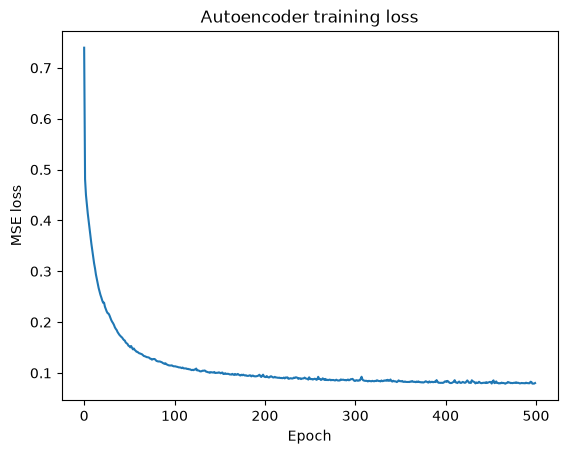

In [128]:

plt.plot(ae_train_losses)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Autoencoder training loss")
plt.show()



### Your task: visualize reconstructions

Run `X_test` through the trained `ae` and scatter-plot the **original test
points** and their **reconstructions** on the same axes, in two different
colors, with a legend. Don't forget `.detach().cpu().numpy()` before
plotting.


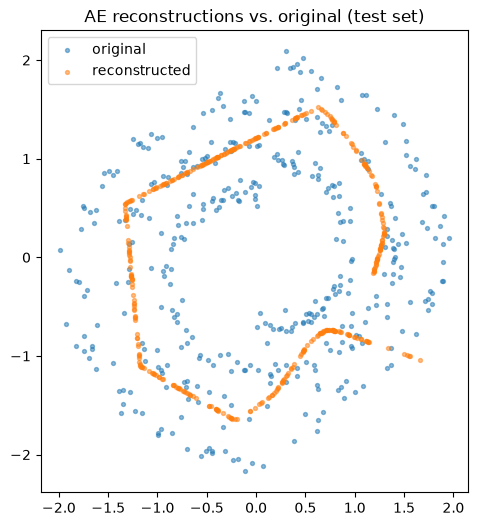

In [129]:
ae.eval()

with torch.no_grad():
    X_test_tensor = X_test_tensor.to(device)
    X_test_recon = ae(X_test_tensor).cpu().numpy() # reconstructed points in original 2D space

X_test_tensor_np = X_test_tensor.cpu().numpy()


plt.figure(figsize=(6, 6))
plt.scatter(X_test_tensor_np[:, 0], X_test_tensor_np[:, 1], s=8, alpha=0.5, label="original")
plt.scatter(X_test_recon[:, 0], X_test_recon[:, 1], s=8, alpha=0.5, label="reconstructed")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("AE reconstructions vs. original (test set)")
plt.show()

Expected, because 1D latent space => single kinky curve (piece-wise linear curve because of the underlying network structure)

Can't place point on both curves simulteniously


## 4. The payoff: visualizing the learned curve directly

Because `LATENT_DIM = 1`, the decoder is a function from a single number to
a 2D point.

### Your task

1. Encode all of `X_train` to get their latent codes `z` (you'll need this
   to know what range of `z` values the model actually learned to use).
2. Build `z_sweep = np.linspace(z.min(), z.max(), 200).reshape(-1, 1)`,
   convert to a tensor, and decode it through `ae.decoder`.
3. Plot the swiss roll scatter (light gray, like the PCA plot) with this
   decoded curve drawn over it in a bold color.


**What if the latent space was not continuous?**

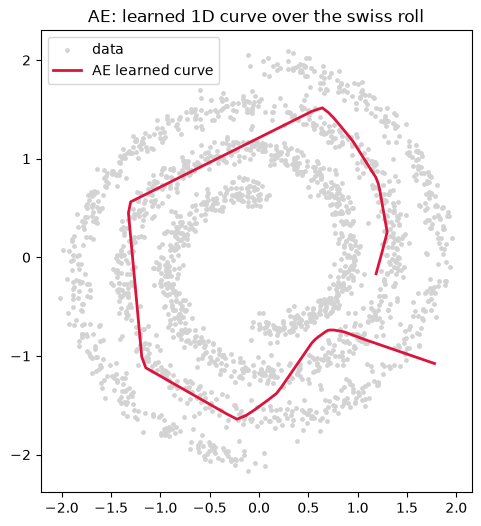

In [130]:
ae.eval()
with torch.no_grad():
    z_train = ae.encoder(torch.FloatTensor(X_train).to(device)).cpu().numpy()


z_sweep = np.linspace(z_train.min(), z_train.max(), 200).reshape(-1, 1)
z_sweep_tensor = torch.FloatTensor(z_sweep).to(device)

with torch.no_grad():
    curve = ae.decoder(z_sweep_tensor).cpu().numpy()


plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=6, color="lightgray", label="data")
plt.plot(curve[:, 0], curve[:, 1], color="crimson", linewidth=2, label="AE learned curve")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("AE: learned 1D curve over the swiss roll")
plt.show()




Visual signature of asking a
1-dimensional bottleneck to represent a manifold that doesn't actually have
1-dimensional topology. 



## 5. Variational Autoencoder (VAE)

### Theory: the Gaussian decoder, made concrete

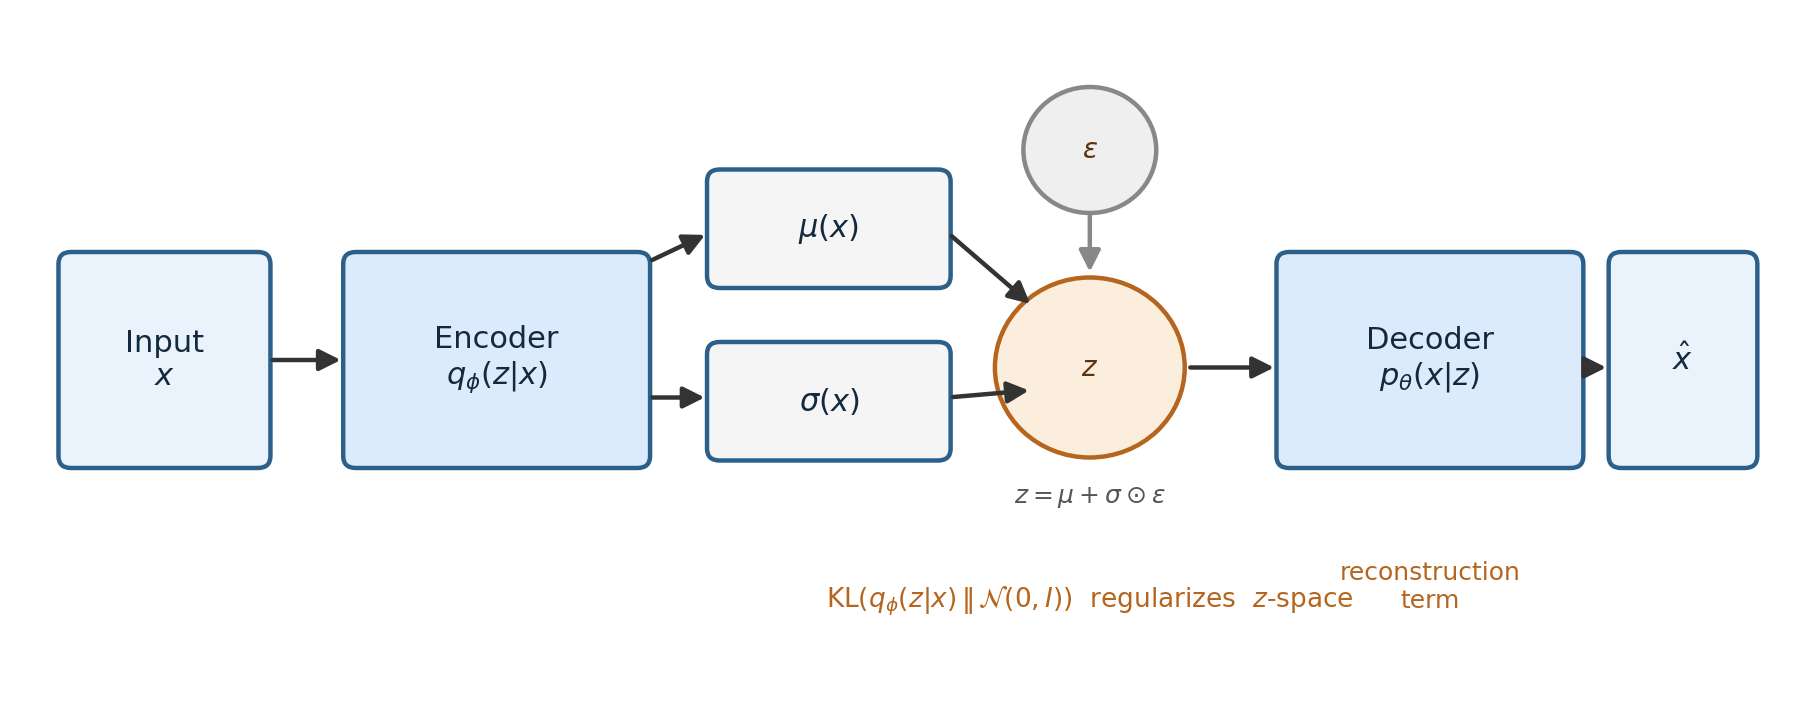

$$
\mathcal{L}_{\text{VAE}} = \underbrace{-\,\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x\mid z)\big]}_{\text{reconstruction term}} \;+\; \underbrace{D_{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{regularization term}}
$$

$$
D_{KL} = \frac{1}{2}\sum_{j=1}^{k}\Big(\mu_j^2 + \sigma_j^2 - \log \sigma_j^2 - 1\Big)
$$

In the MNIST notebook, the reconstruction term became binary cross-entropy
because pixels were treated as Bernoulli-distributed. Here, there's no such
assumption to make — the natural choice is a **Gaussian** decoder
distribution, $p_\theta(x\mid z) = \mathcal{N}(g_\theta(z), I)$, and under a
Gaussian with fixed variance, $-\log p_\theta(x\mid z)$ reduces (up to an
additive constant that doesn't affect gradients) to exactly:

$$
\lVert x - g_\theta(z) \rVert_2^2
$$

— plain MSE. This is the same general ELBO as before; only the assumed
shape of the decoder's output distribution changed, and that choice is what
determined the loss function in both notebooks. Everything about
`reparameterize` and the KL term is completely unchanged from MNIST.


**The encoder-conditioned sampling (mu + std*eps for a real x) is training-only in how this notebook uses it.**


### Your task: implement `VAEEncoder`, `reparameterize`, `VAE`, `vae_loss`

Same structure as the MNIST notebook:

- `VAEEncoder`: shared trunk `Linear(input_dim, hidden_dim)` → `ReLU`, then
  two heads `Linear(hidden_dim, latent_dim)` for `mu` and for `logvar`.
- `reparameterize(mu, logvar)`: $z = \mu + \sigma \odot \epsilon$, with
  `std = torch.exp(0.5 * logvar)` and `eps = torch.randn_like(std)`.
- `VAE`: wires `VAEEncoder` → `reparameterize` → `Decoder` (reuse the
  `Decoder` class you already wrote — it doesn't change for a VAE).
  `forward(x)` returns `x_hat, mu, logvar`.
- `vae_loss(x_hat, x, mu, logvar)`: MSE reconstruction term (use
  `reduction='sum'` here, then divide by batch size, so it's on a comparable
  scale to the summed KL term below — unlike the plain-mean AE loss above)
  plus the closed-form KL term (summed over latent dims, divided by batch
  size). Return `recon_loss, kl_loss, total_loss`.


In [131]:

class VAEEncoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        h = self.trunk(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar


def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + std * eps


class VAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = VAEEncoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = reparameterize(mu, logvar)
        x_hat = self.decoder(z)
        return x_hat, mu, logvar


def vae_loss(x_hat, x, mu, logvar):
    batch_size = x.size(0)
    recon_loss = F.mse_loss(x_hat, x, reduction='sum') / batch_size
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    total_loss = recon_loss + kl_loss
    return recon_loss, kl_loss, total_loss


In [132]:

# Sanity checks
mu_test = torch.zeros(200, LATENT_DIM)
logvar_test = torch.full((200, LATENT_DIM), -10.0)
z_test = reparameterize(mu_test, logvar_test)
assert z_test.shape == mu_test.shape
assert torch.allclose(z_test, mu_test, atol=0.05)

vae = VAE().to(device)
dummy_x = torch.randn(4, INPUT_DIM).to(device)
x_hat, mu, logvar = vae(dummy_x)
assert x_hat.shape == dummy_x.shape
assert mu.shape == (4, LATENT_DIM)
assert logvar.shape == (4, LATENT_DIM)

print("VAE components look correct.")


VAE components look correct.



### Your task: the VAE training loop

Same pattern as the MNIST notebook's VAE loop — track `recon_loss` and
`kl_loss` separately (not just their sum), for the same posterior-collapse
monitoring reason covered there.


In [133]:

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=LR)

vae_recon_losses = []
vae_kl_losses = []

for epoch in range(EPOCHS):
    epoch_recon = 0.0
    epoch_kl = 0.0
    n_batches = 0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, logvar = vae(x)
        recon_loss, kl_loss, loss = vae_loss(x_hat, x, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_recon += recon_loss.item()
        epoch_kl += kl_loss.item()
        n_batches += 1

    epoch_recon /= n_batches
    epoch_kl /= n_batches
    vae_recon_losses.append(epoch_recon)
    vae_kl_losses.append(epoch_kl)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} — recon: {epoch_recon:.4f}, KL: {epoch_kl:.4f}")


Epoch 20/500 — recon: 1.3582, KL: 0.4022
Epoch 40/500 — recon: 1.1846, KL: 0.5442
Epoch 60/500 — recon: 1.1489, KL: 0.5681
Epoch 80/500 — recon: 1.0789, KL: 0.6182
Epoch 100/500 — recon: 1.0848, KL: 0.6190
Epoch 120/500 — recon: 1.1380, KL: 0.6485
Epoch 140/500 — recon: 1.0847, KL: 0.6320
Epoch 160/500 — recon: 1.0485, KL: 0.6327
Epoch 180/500 — recon: 1.0478, KL: 0.6489
Epoch 200/500 — recon: 1.0375, KL: 0.6499
Epoch 220/500 — recon: 1.0213, KL: 0.6708
Epoch 240/500 — recon: 0.9945, KL: 0.6790
Epoch 260/500 — recon: 1.0378, KL: 0.6898
Epoch 280/500 — recon: 0.9959, KL: 0.7132
Epoch 300/500 — recon: 1.0320, KL: 0.7029
Epoch 320/500 — recon: 1.0166, KL: 0.6851
Epoch 340/500 — recon: 0.9911, KL: 0.6806
Epoch 360/500 — recon: 0.9815, KL: 0.7053
Epoch 380/500 — recon: 0.9815, KL: 0.7080
Epoch 400/500 — recon: 0.9661, KL: 0.7029
Epoch 420/500 — recon: 0.9955, KL: 0.6806
Epoch 440/500 — recon: 1.0103, KL: 0.7050
Epoch 460/500 — recon: 0.9831, KL: 0.7092
Epoch 480/500 — recon: 0.9995, KL: 0.6

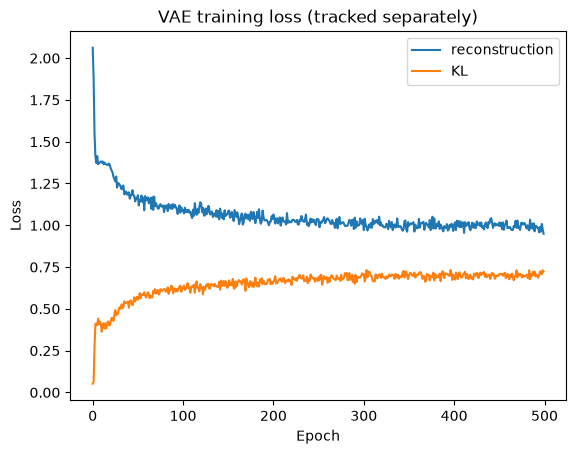

In [134]:

plt.plot(vae_recon_losses, label="reconstruction")
plt.plot(vae_kl_losses, label="KL")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("VAE training loss (tracked separately)")
plt.show()



## 6. The VAE's curve, and generating along it

### Your task: plot the VAE's learned curve

Same exercise as Section 4, but using `vae.encoder` (use `mu`, not a random
sample — see the MNIST notebook's reasoning) to find the observed latent
range, and `vae.decoder` to decode the sweep.


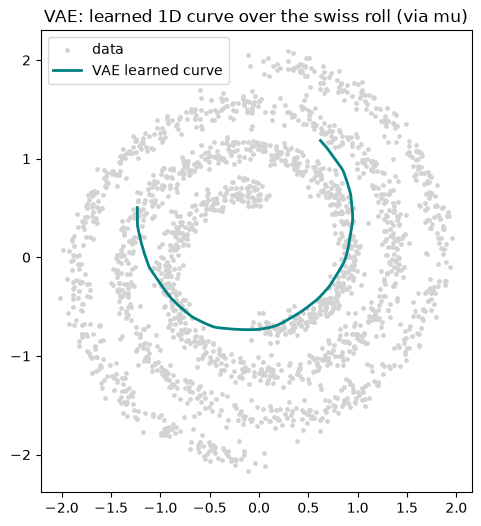

In [135]:

vae.eval()
with torch.no_grad():
    mu_train, _ = vae.encoder(torch.FloatTensor(X_train).to(device))
    mu_train = mu_train.cpu().numpy()

z_sweep_vae = np.linspace(mu_train.min(), mu_train.max(), 200).reshape(-1, 1)
z_sweep_vae_tensor = torch.FloatTensor(z_sweep_vae).to(device)

with torch.no_grad():
    vae_curve = vae.decoder(z_sweep_vae_tensor).cpu().numpy()

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=6, color="lightgray", label="data")
plt.plot(vae_curve[:, 0], vae_curve[:, 1], color="teal", linewidth=2, label="VAE learned curve")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("VAE: learned 1D curve over the swiss roll (via mu)")
plt.show()



### Your task: generate new points from the prior

Unlike the AE, the VAE's latent space is explicitly regularized toward
$\mathcal{N}(0, I)$ — so you don't need to check the observed range first.
Sample `z ~ N(0,1)` directly (shape `(200, 1)`), decode, and scatter the
results over the real data. If training went well, generated points should
land convincingly along the spiral, not scattered randomly across the plot.


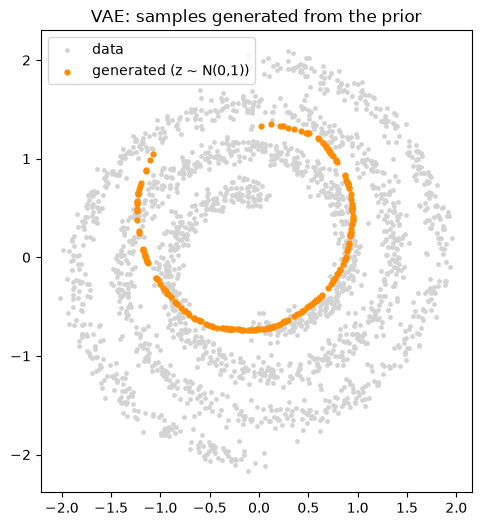

In [ ]:

vae.eval()
n_gen = 200
z_prior = torch.randn(n_gen, LATENT_DIM).to(device) # this is a sample from the prior N(0,1) Gaussian distribution in the latent space

with torch.no_grad():
    generated = vae.decoder(z_prior).cpu().numpy()

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=6, color="lightgray", label="data")
plt.scatter(generated[:, 0], generated[:, 1], s=12, color="darkorange", label="generated (z ~ N(0,1))")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("VAE: samples generated from the prior")
plt.show()



### Your task: check whether the encoded points actually follow the prior

The KL term in `vae_loss` exists to pull every point's `(mu, logvar)` toward
the standard normal distribution `N(0,1)` — that's the "prior" referred to
above. This task checks, empirically, whether that actually happened: if you
gather the `mu` the trained encoder produces for every training point and
look at their distribution as a whole, does it resemble a bell curve
centered at 0, or something else?

You already have `mu_train` from the previous cell (the encoded `mu` for
   every training point) — reuse it here, no need to re-encode.


What to look for:
- **Good sign**: the histogram bars roughly trace the black `N(0,1)` curve —
  bell-shaped, centered near 0, width near 1. The KL term succeeded in
  spreading `mu` out to fill the prior.
- **Bad sign (posterior collapse)**: almost all `mu` values pile into a
  narrow spike at 0, ignoring the input `x` entirely — the encoder gave up
  encoding any real information, since outputting ~0 for everything
  trivially satisfies the KL term. Same failure mode as the MNIST notebook,
  now directly visible as a spike instead of inferred from a flat KL curve.


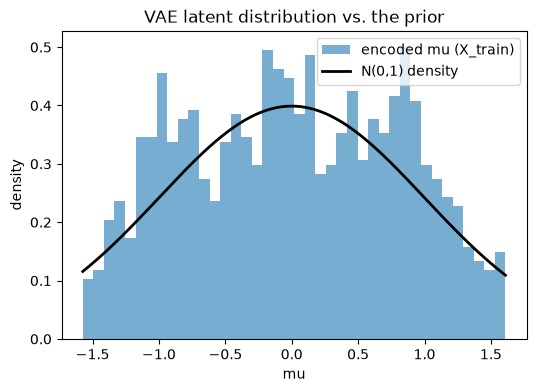

In [ ]:

from scipy.stats import norm

# mu_train comes from encoding X_train data through a trained VAE encoder.

plt.figure(figsize=(6, 4))
plt.hist(mu_train.ravel(), bins=40, density=True, alpha=0.6, label="encoded mu (X_train)")

xs = np.linspace(mu_train.min(), mu_train.max(), 200) 
plt.plot(xs, norm.pdf(xs), color="black", linewidth=2, label="N(0,1) density")

plt.xlabel("mu")
plt.ylabel("density")
plt.legend()
plt.title("VAE latent distribution vs. the prior")
plt.show()


The KL term pulls that individual distribution toward N(0,1). For every single x in a batch, vae_loss adds a penalty for how far (mu, logvar) for that point is from N(0,1). So training is constantly tugging every point's little distribution back toward centered-at-0, width-1 — while reconstruction loss is simultaneously pulling different points toward different mu values (so they stay distinguishable). Training settles at a compromise between these two opposing forces.


## 6.5. Reproducing the noise (single arm)

Section 6 generates points that land *exactly on* the learned curve — because
`Decoder` is deterministic: one `z` always maps to exactly one `x_hat`. Real
data isn't like that — it scatters around the curve (`NOISE`). If you want
generated points that also look like a genuine draw from the data
distribution, noise and all, the decoder itself needs to become
probabilistic: instead of outputting a single point, it outputs a *Gaussian*
over points — a mean `mu_x(z)` and a variance `logvar_x(z)`, exactly the same
idea `VAEEncoder` already uses for the latent space, just applied to the
output side too.

This reuses your existing `VAEEncoder` and `reparameterize` from Section 5
unchanged — **only the decoder and loss are new** — and is applied here to the
**single spiral arm** (`X_train_single`, `train_loader_single` from Section
0.5) rather than the full two-armed dataset.


In [ ]:

class GaussianDecoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, hidden_dim=HIDDEN_DIM, output_dim=INPUT_DIM):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, output_dim)
        self.fc_logvar = nn.Linear(hidden_dim, output_dim) # Since they have separate weights, during training they'll learn completely different transformations even though the architecture

    def forward(self, z):
        h = self.trunk(z)
        mu_x = self.fc_mu(h)
        logvar_x = self.fc_logvar(h)
        return mu_x, logvar_x


class VAEGaussianSingle(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = VAEEncoder(input_dim, hidden_dim, latent_dim)   # reused from Section 5
        self.decoder = GaussianDecoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        mu_z, logvar_z = self.encoder(x)
        z = reparameterize(mu_z, logvar_z)   # reused from Section 5
        mu_x, logvar_x = self.decoder(z)
        return mu_x, logvar_x, mu_z, logvar_z


def vae_gaussian_loss(mu_x, logvar_x, x, mu_z, logvar_z):
    batch_size = x.size(0)
    # Gaussian negative log-likelihood of x under N(mu_x, exp(logvar_x)),
    # in place of MSE — the decoder now predicts its own uncertainty too.
    recon_nll = 0.5 * torch.sum(logvar_x + (x - mu_x).pow(2) / torch.exp(logvar_x)) / batch_size
    kl_loss = -0.5 * torch.sum(1 + logvar_z - mu_z.pow(2) - logvar_z.exp()) / batch_size
    total_loss = recon_nll + kl_loss
    return recon_nll, kl_loss, total_loss


In [152]:

vae_gauss_single = VAEGaussianSingle().to(device)
optimizer_gauss_single = torch.optim.Adam(vae_gauss_single.parameters(), lr=LR)

vae_gauss_single_recon_losses = []
vae_gauss_single_kl_losses = []

for epoch in range(EPOCHS*50):
    epoch_recon = 0.0
    epoch_kl = 0.0
    n_batches = 0
    for x, _ in train_loader_single:
        x = x.to(device)
        mu_x, logvar_x, mu_z, logvar_z = vae_gauss_single(x)
        recon_loss, kl_loss, loss = vae_gaussian_loss(mu_x, logvar_x, x, mu_z, logvar_z)

        optimizer_gauss_single.zero_grad()
        loss.backward()
        optimizer_gauss_single.step()

        epoch_recon += recon_loss.item()
        epoch_kl += kl_loss.item()
        n_batches += 1

    epoch_recon /= n_batches
    epoch_kl /= n_batches
    vae_gauss_single_recon_losses.append(epoch_recon)
    vae_gauss_single_kl_losses.append(epoch_kl)
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS*50} — recon NLL: {epoch_recon:.4f}, KL: {epoch_kl:.4f}")


Epoch 100/25000 — recon NLL: -0.3791, KL: 1.2070
Epoch 200/25000 — recon NLL: -0.6486, KL: 1.4580
Epoch 300/25000 — recon NLL: -0.9239, KL: 1.6876
Epoch 400/25000 — recon NLL: -1.0623, KL: 1.8049
Epoch 500/25000 — recon NLL: -1.0526, KL: 1.8020
Epoch 600/25000 — recon NLL: -1.1237, KL: 1.8816
Epoch 700/25000 — recon NLL: -1.0733, KL: 1.8233
Epoch 800/25000 — recon NLL: -1.1397, KL: 1.8762
Epoch 900/25000 — recon NLL: -1.2063, KL: 1.9299
Epoch 1000/25000 — recon NLL: -1.2255, KL: 1.9881
Epoch 1100/25000 — recon NLL: -1.2887, KL: 2.0108
Epoch 1200/25000 — recon NLL: -1.2313, KL: 1.9706
Epoch 1300/25000 — recon NLL: -1.2114, KL: 1.9527
Epoch 1400/25000 — recon NLL: -1.2620, KL: 1.9932
Epoch 1500/25000 — recon NLL: -1.2750, KL: 2.0488
Epoch 1600/25000 — recon NLL: -1.3647, KL: 2.0840
Epoch 1700/25000 — recon NLL: -1.3785, KL: 2.0993
Epoch 1800/25000 — recon NLL: -1.3478, KL: 2.0739
Epoch 1900/25000 — recon NLL: -1.3592, KL: 2.1097
Epoch 2000/25000 — recon NLL: -1.3943, KL: 2.0726
Epoch 210

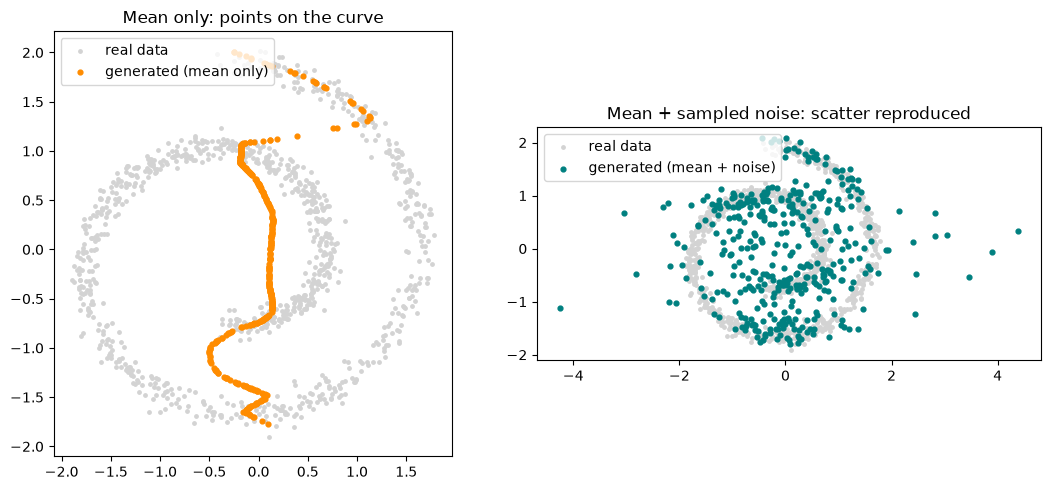

In [153]:

vae_gauss_single.eval()
n_gen = 400
z_prior_single = torch.randn(n_gen, LATENT_DIM).to(device)

with torch.no_grad():
    mu_x_gen, logvar_x_gen = vae_gauss_single.decoder(z_prior_single)
    x_gen_mean_single = mu_x_gen.cpu().numpy()                                     # on the curve only
    x_gen_sampled_single = reparameterize(mu_x_gen, logvar_x_gen).cpu().numpy()    # + sampled output noise

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].scatter(X_single[:, 0], X_single[:, 1], s=6, color="lightgray", label="real data")
axes[0].scatter(x_gen_mean_single[:, 0], x_gen_mean_single[:, 1], s=12, color="darkorange", label="generated (mean only)")
axes[0].set_title("Mean only: points on the curve")
axes[0].legend()
axes[0].set_aspect("equal")

axes[1].scatter(X_single[:, 0], X_single[:, 1], s=6, color="lightgray", label="real data")
axes[1].scatter(x_gen_sampled_single[:, 0], x_gen_sampled_single[:, 1], s=12, color="teal", label="generated (mean + noise)")
axes[1].set_title("Mean + sampled noise: scatter reproduced")
axes[1].legend()
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()


**Why is the VAE here worse than AE for single arm?** **Note: Gaussian-NLL specific: the model can "cheat" via variance instead of tightening the mean.**


## 7. Do the latent codes separate the two spiral arms?

### Your task: a first visual gut-check

For the AE, plot **two overlapping histograms** of `z` (the training-set
latent codes from Section 4) — one for points where `y_train == 0`, one for
`y_train == 1` .


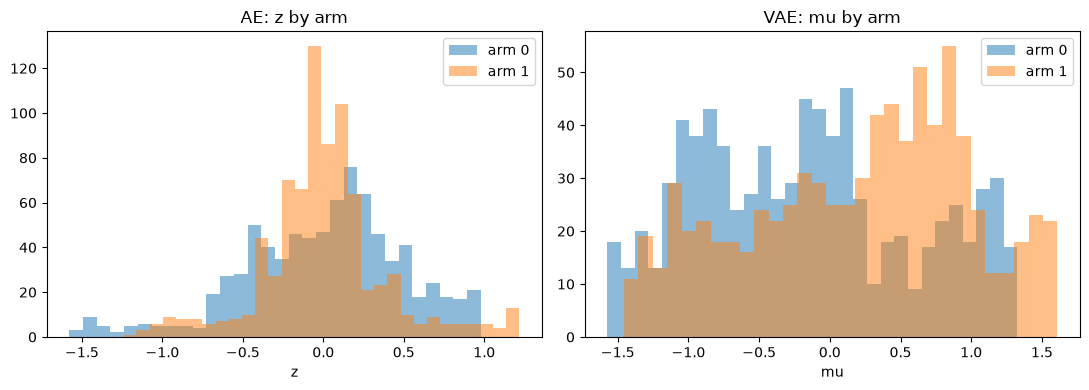

In [158]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(z_train[y_train == 0], bins=30, alpha=0.5, label="arm 0")
axes[0].hist(z_train[y_train == 1], bins=30, alpha=0.5, label="arm 1")
axes[0].set_title("AE: z by arm")
axes[0].set_xlabel("z")
axes[0].legend()

axes[1].hist(mu_train[y_train == 0], bins=30, alpha=0.5, label="arm 0")
axes[1].hist(mu_train[y_train == 1], bins=30, alpha=0.5, label="arm 1")
axes[1].set_title("VAE: mu by arm")
axes[1].set_xlabel("mu")
axes[1].legend()

plt.tight_layout()
plt.show()


### Your task: quantify quality of classification by AE with a classifier


This fits two classifiers directly on the AE's 1D latent code (`z_train`,
`z_test`) and checks accuracy on **held-out** points -- i.e. points the
classifier never saw while fitting -- which is the only fair way to know if
it learned real structure vs. just memorized the training points.

1. Encode `X_train` and `X_test` through `ae.encoder` to get `z_train`,
   `z_test` (as numpy arrays).
2. Fit `sklearn.linear_model.LogisticRegression()` on `(z_train, y_train)`,
   then `.score(z_test, y_test)`.
3. Fit `sklearn.neighbors.KNeighborsClassifier(n_neighbors=5)` the same way.
4. Compare both scores to the trivial baseline of always guessing the
   majority class: `max(y_test.mean(), 1 - y_test.mean())`.

**What the three printed numbers mean, and how to read them:**
- **Baseline** -- not a real classifier. It's "how accurate would I be if I
  ignored `z` completely and always guessed whichever arm is more common in
  the test set?" Since the split is close to 50/50, this lands a bit above
  0.5. Any real classifier has to beat this number to prove it learned
  something from `z` at all.
- **Logistic regression** -- a *linear* classifier: in 1D, this means a
  single threshold value on `z` ("arm 0 if `z < t`, else arm 1"). If this
  score is at or below baseline, it means no single cut point on the 1D
  code reliably separates the two arms.
- **KNN (k=5)** -- a *local/nonlinear* classifier: to classify a point, look
  at its 5 nearest neighbors in `z` and vote. If this beats both the
  baseline and logistic regression, it means points close together in `z`
  do tend to share an arm -- there's real local structure -- even though no
  single global threshold captures it.

**What to expect, and why.** Both classifiers should land *above* the
baseline, typically by something like 5-15 percentage points -- the two arms
really are somewhat distinguishable from a 1D code, since a point's position
along the zigzag curve from Section 4 carries some information about which
arm it's nearest to. Don't be surprised, though, if the gap between the two
classifiers is small, or if logistic regression occasionally even *wins* --
across different random seeds this is a genuinely close, noisy contest,
not a clean linear-loses-to-nonlinear story. That's informative in its own
right: a 1-dimensional code squeezed from two interleaved arms only has so
much room to encode "which arm," and whatever structure survives doesn't
consistently favor one kind of classifier over the other. Keep this result
in mind for contrast with the bonus exercise below, where the picture
changes substantially.

In [165]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# AE ONLY here -- see the markdown note above for why the VAE isn't included.
ae.eval()
with torch.no_grad():
    # z_train_ae / z_test_ae: the AE's 1D bottleneck code for every point,
    # computed once so both classifiers below reuse the same codes.
    z_train_ae = ae.encoder(torch.FloatTensor(X_train).to(device)).cpu().numpy()
    z_test_ae = ae.encoder(torch.FloatTensor(X_test).to(device)).cpu().numpy()

# Trivial reference point: accuracy from always guessing the more common
# arm in the test set, ignoring z entirely. Any real classifier must beat this.
baseline = max(y_test.mean(), 1 - y_test.mean())

# Linear classifier: in 1D this is just a single threshold on z
# ("arm 0 if z < t, else arm 1"). Fit on train codes, scored on held-out codes.
logreg = LogisticRegression()
logreg.fit(z_train_ae, y_train)
logreg_acc = logreg.score(z_test_ae, y_test)

# Local/nonlinear classifier: classifies each point by majority vote among
# its 5 nearest neighbors in z-space. Can pick up structure a single global
# threshold (logistic regression) would miss.
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(z_train_ae, y_train)
knn_acc = knn.score(z_test_ae, y_test)

print(f"Majority-class baseline: {baseline:.4f}")
print(f"Logistic regression accuracy: {logreg_acc:.4f}")
print(f"KNN (k=5) accuracy: {knn_acc:.4f}")


Majority-class baseline: 0.5125
Logistic regression accuracy: 0.4875
KNN (k=5) accuracy: 0.6275



### Does a 2D latent space change the picture?

Go back to the hyperparameters cell, set `LATENT_DIM = 2`, and re-run the AE
class definitions, sanity check, and training loop cells (VAE too, if you
like). Then:

1. Produce a 2D scatter plot of `z` (from the retrained AE), colored by
   `y_train` — the same kind of plot as the MNIST notebook's Section 3,
   just with 2 classes instead of 10 digits this time.
2. Re-run both classifier checks from above on this new 2D `z`.

**One thing worth noticing going in:** with `LATENT_DIM = 2` on 2D input
data, the bottleneck stops being a real bottleneck — the model is no longer
forced to compress anything, so reconstruction error can drop dramatically
compared to the 1D case.

**Now expect a genuinely different, much more dramatic result than the 1D
case:** KNN accuracy should jump to something close to perfect — the two
arms become almost completely separable locally once there's a second
dimension to work with. Logistic regression, meanwhile, t\ypically only
inches up into a similar modest range as before. With two dimensions, the
arms have room to become *locally* very well separated (great for KNN)
without ever becoming separable by one straight line (the interleaving is a
genuinely nonlinear, not just under-dimensioned, structure) — so unlike the
1D case, this time the linear/nonlinear gap should show up clearly and
reliably.


In [172]:

LATENT_DIM_2D = 2

# Retrain a fresh AE with a 2D bottleneck. Reuses the same Encoder/Decoder/
# Autoencoder classes and the same train_loader (built from 2D X_train,
# independent of latent_dim) -- only latent_dim changes.
ae_2d = Autoencoder(input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM_2D).to(device)
optimizer_2d = torch.optim.Adam(ae_2d.parameters(), lr=LR)

ae_2d_train_losses = []
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    n_batches = 0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat = ae_2d(x)
        loss = F.mse_loss(x_hat, x)

        optimizer_2d.zero_grad()
        loss.backward()
        optimizer_2d.step()

        epoch_loss += loss.item()
        n_batches += 1

    epoch_loss /= n_batches
    ae_2d_train_losses.append(epoch_loss)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} — AE(2D) loss: {epoch_loss:.4f}")

# With no real bottleneck (2D code for 2D data), reconstruction loss should
# drop well below the 1D run's -- the model no longer has to compress anything.
print(f"\nFinal reconstruction loss — 1D bottleneck: {ae_train_losses[-1]:.4f}, "
      f"2D bottleneck: {ae_2d_train_losses[-1]:.4f}")


Epoch 20/500 — AE(2D) loss: 0.0002
Epoch 40/500 — AE(2D) loss: 0.0001
Epoch 60/500 — AE(2D) loss: 0.0000
Epoch 80/500 — AE(2D) loss: 0.0000
Epoch 100/500 — AE(2D) loss: 0.0000
Epoch 120/500 — AE(2D) loss: 0.0000
Epoch 140/500 — AE(2D) loss: 0.0000
Epoch 160/500 — AE(2D) loss: 0.0000
Epoch 180/500 — AE(2D) loss: 0.0000
Epoch 200/500 — AE(2D) loss: 0.0000
Epoch 220/500 — AE(2D) loss: 0.0000
Epoch 240/500 — AE(2D) loss: 0.0000
Epoch 260/500 — AE(2D) loss: 0.0000
Epoch 280/500 — AE(2D) loss: 0.0000
Epoch 300/500 — AE(2D) loss: 0.0000
Epoch 320/500 — AE(2D) loss: 0.0000
Epoch 340/500 — AE(2D) loss: 0.0000
Epoch 360/500 — AE(2D) loss: 0.0000
Epoch 380/500 — AE(2D) loss: 0.0000
Epoch 400/500 — AE(2D) loss: 0.0000
Epoch 420/500 — AE(2D) loss: 0.0000
Epoch 440/500 — AE(2D) loss: 0.0000
Epoch 460/500 — AE(2D) loss: 0.0000
Epoch 480/500 — AE(2D) loss: 0.0000
Epoch 500/500 — AE(2D) loss: 0.0000

Final reconstruction loss — 1D bottleneck: 0.0802, 2D bottleneck: 0.0000


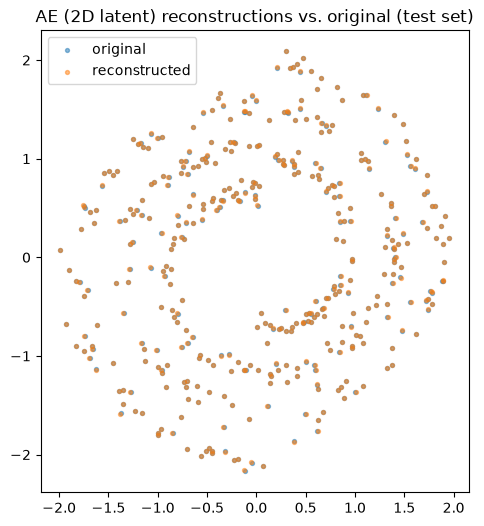

In [173]:
# --- Reconstruction quality check (test set, same convention as Section 2) ---
# Uses X_test, not X_train: the model was directly optimized to reconstruct
# X_train, so testing on it mostly just confirms the loss function worked.
# X_test shows how well the 2D bottleneck generalizes to unseen points.
ae_2d.eval()
with torch.no_grad():
    X_test_recon_2d = ae_2d(torch.FloatTensor(X_test).to(device)).cpu().numpy()

plt.figure(figsize=(6, 6))
plt.scatter(X_test[:, 0], X_test[:, 1], s=8, alpha=0.5, label="original")
plt.scatter(X_test_recon_2d[:, 0], X_test_recon_2d[:, 1], s=8, alpha=0.5, label="reconstructed")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("AE (2D latent) reconstructions vs. original (test set)")
plt.show()

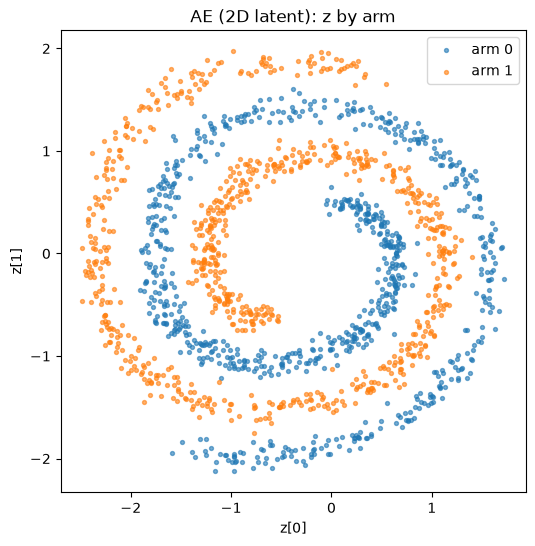

Majority-class baseline: 0.5125
Logistic regression accuracy (2D z): 0.6500
KNN (k=5) accuracy (2D z): 0.9950


In [174]:
# --- 2D latent scatter, colored by arm ---
ae_2d.eval()
with torch.no_grad():
    z_train_2d = ae_2d.encoder(torch.FloatTensor(X_train).to(device)).cpu().numpy()
    z_test_2d = ae_2d.encoder(torch.FloatTensor(X_test).to(device)).cpu().numpy()

plt.figure(figsize=(6, 6))
plt.scatter(z_train_2d[y_train == 0, 0], z_train_2d[y_train == 0, 1], s=8, alpha=0.6, label="arm 0")
plt.scatter(z_train_2d[y_train == 1, 0], z_train_2d[y_train == 1, 1], s=8, alpha=0.6, label="arm 1")
plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.legend()
plt.title("AE (2D latent): z by arm")
plt.show()

# --- Re-run both classifier checks on the 2D code ---
# LogisticRegression / KNeighborsClassifier already imported above (Section 7).
baseline_2d = max(y_test.mean(), 1 - y_test.mean())

logreg_2d = LogisticRegression()
logreg_2d.fit(z_train_2d, y_train)
logreg_acc_2d = logreg_2d.score(z_test_2d, y_test)

knn_2d = KNeighborsClassifier(n_neighbors=5)
knn_2d.fit(z_train_2d, y_train)
knn_acc_2d = knn_2d.score(z_test_2d, y_test)

print(f"Majority-class baseline: {baseline_2d:.4f}")
print(f"Logistic regression accuracy (2D z): {logreg_acc_2d:.4f}")
print(f"KNN (k=5) accuracy (2D z): {knn_acc_2d:.4f}")



## 8. Bonus: what does the bottleneck do with noise?

Go back to Section 1 and change `NOISE` — try `0.1` (much cleaner spiral)
and `1.5` (much noisier) — then re-run the whole notebook top to bottom for
each value.

**What to look for:** a bottlenecked model can't memorize every noisy point
individually (that's the entire point of the bottleneck), so it's forced to
find a single smooth curve that reasonably explains *all* the noisy points
at once. This is precisely what a regression line does with noisy 1D
data — it doesn't zigzag through every point, it smooths through them. Watch
whether the learned curve tracks the noise (bad — this would suggest the
bottleneck isn't constraining enough, or training has run too long) or
stays smooth and central through the noisy scatter (expected, and a nice
concrete demonstration of the bottleneck acting as a regularizer).



## 10. Where this leaves you

Between this notebook and the MNIST one, you've now implemented the same AE
and VAE building blocks under two genuinely different data regimes:

| | MNIST notebook | This notebook |
|---|---|---|
| Data | high-dim, pixels in `[0,1]` | low-dim, unbounded coordinates |
| Decoder output layer | `Sigmoid` | none (plain `Linear`) |
| Reconstruction loss | BCE | MSE |
| What the bottleneck buys you | compression, generation | a literal, visualizable regression curve |
| Latent space check | 2D scatter plot | 1D histogram vs. the prior |
| Class information | 10 digit classes, for coloring only | 2 distinct spiral arms — you tested this directly in Section 7 |

If the code in this notebook felt more like "the same thing again" than
"something new to learn," that's the intended outcome — the underlying
mechanics (encoder/decoder shape, reparameterization, the ELBO, the training
loop) don't actually depend on images at all. Everything image-specific in
the MNIST notebook was a detail sitting on top of that same core.

Section 7 is worth reflecting on a bit more: a purely unsupervised
reconstruction objective ended up preserving real class-relevant structure
with no label anywhere in the loss. How *accessible* that structure was
depended heavily on dimensionality — modest and roughly classifier-agnostic
at a 1D bottleneck, then sharply favoring a nonlinear reader once a second
latent dimension gave the two arms room to separate locally without ever
becoming linearly separable. "Structure exists" and "structure is linearly
readable" are genuinely different questions, and conflating them is a very
common mistake when inspecting learned representations well beyond this toy
example.
